In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [3]:
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutant Meteorologi Lubang buaya.xlsx"
df = pd.read_excel(df_path)

In [4]:
df

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,2022-01-01 00:00:00,35.0,47.8,37.2,6.2,13.2,9.8,25.36,0,22.94,0.45,90.48,2.59
1,2022-01-01 01:00:00,37.4,42.0,49.8,12.2,15.0,12.0,25.79,0,22.82,0.00,91.54,2.59
2,2022-01-01 02:00:00,48.6,80.0,48.0,7.8,17.2,15.4,28.41,0,22.98,0.00,92.67,2.57
3,2022-01-01 03:00:00,45.2,74.6,48.6,8.8,17.2,15.2,28.93,0,22.93,0.06,94.11,2.54
4,2022-01-01 04:00:00,52.4,80.8,52.6,10.6,17.6,14.6,29.64,0,22.78,0.18,95.80,2.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,2024-12-31 19:00:00,30.0,16.0,22.0,6.0,20.0,9.0,25.14,0,23.05,0.26,93.81,2.51
26300,2024-12-31 20:00:00,30.0,16.0,22.0,6.0,20.0,9.0,24.61,0,22.89,0.07,94.53,2.58
26301,2024-12-31 21:00:00,31.0,17.0,22.0,7.0,20.0,9.0,24.56,0,22.91,0.01,95.57,2.63
26302,2024-12-31 22:00:00,31.0,18.0,22.0,7.0,20.0,9.0,24.60,0,22.84,0.01,96.97,2.62


In [5]:
df.dtypes

,0
datetime,datetime64[ns]
PM10,float64
PM2.5,float64
SO2,float64
CO,float64
O3,float64
NO2,float64
Suhu Udara,float64
Radiasi Matahari,int64
Suhu Titik Embun,float64


In [6]:
df.isnull().sum()

,0
datetime,0
PM10,0
PM2.5,0
SO2,0
CO,0
O3,0
NO2,0
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [7]:
df.isnull().sum()

,0
datetime,0
PM10,0
PM2.5,0
SO2,0
CO,0
O3,0
NO2,0
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [8]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

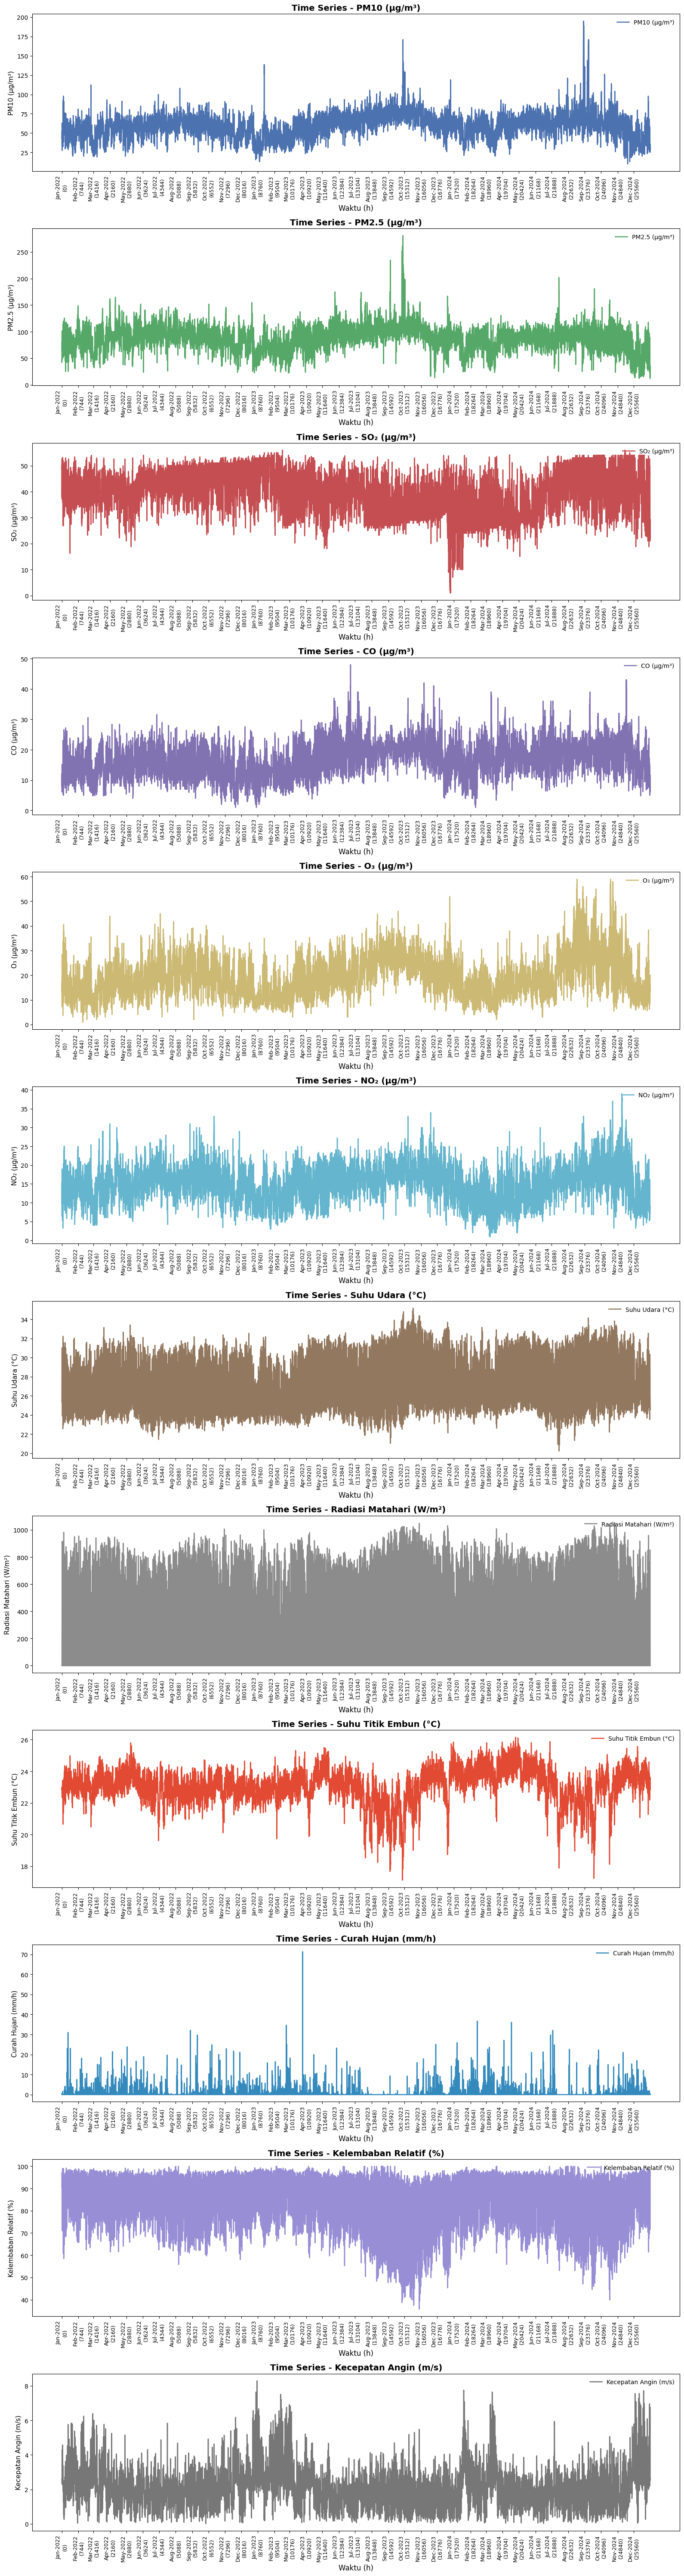

In [9]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)
df_ts = df_ts.sort_index()

hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [10]:
df_ts.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,59.67,87.44,39.37,16.73,19.15,15.07,26.86,217.01,23.04,0.61,85.29,2.04
std,16.23,24.87,9.48,6.17,8.57,5.19,2.58,290.45,1.08,2.08,12.37,1.14
min,10.00,12.00,1.00,1.00,1.00,1.00,20.23,0.00,17.12,0.00,35.73,0.01
25%,50.80,71.80,31.00,12.00,13.00,11.60,24.72,0.00,22.51,0.00,76.49,1.27
50%,61.00,89.00,40.00,16.80,18.00,15.00,26.24,14.00,23.14,0.00,90.50,1.83
75%,69.40,103.00,47.00,21.00,24.00,18.20,28.92,437.00,23.74,0.21,95.35,2.54
max,195.00,281.00,56.00,48.00,59.00,39.00,35.17,1053.00,26.15,71.27,100.00,8.29


In [11]:
df.replace(['-', ''], np.nan, inplace=True)

for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df_numeric = df.drop(columns=["datetime"])
datetime_col = df["datetime"]

In [12]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [13]:
imputer = KNNImputer(n_neighbors=5)
df_scaled_imputed = imputer.fit_transform(df_scaled)

df_imputed = pd.DataFrame(scaler.inverse_transform(df_scaled_imputed), columns=df_numeric.columns)
df_imputed["datetime"] = datetime_col
df_imputed = df_imputed.set_index("datetime")

In [14]:
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
datetime,,,,,,,,,,,,
2022-01-01 00:00:00,35.0,47.8,37.2,6.2,13.2,9.8,25.36,0.0,22.94,4.500000e-01,90.48,2.59
2022-01-01 01:00:00,37.4,42.0,49.8,12.2,15.0,12.0,25.79,0.0,22.82,-1.110223e-16,91.54,2.59
2022-01-01 02:00:00,48.6,80.0,48.0,7.8,17.2,15.4,28.41,0.0,22.98,-1.110223e-16,92.67,2.57
2022-01-01 03:00:00,45.2,74.6,48.6,8.8,17.2,15.2,28.93,0.0,22.93,6.000000e-02,94.11,2.54
2022-01-01 04:00:00,52.4,80.8,52.6,10.6,17.6,14.6,29.64,0.0,22.78,1.800000e-01,95.80,2.45
2022-01-01 05:00:00,42.4,63.6,38.0,9.0,7.4,6.4,30.67,0.0,22.59,4.000000e-01,97.08,2.37
2022-01-01 06:00:00,59.8,87.4,42.6,12.6,17.4,14.8,30.92,90.0,22.65,5.000000e-02,94.24,2.57
2022-01-01 07:00:00,63.0,101.6,50.4,15.2,28.4,19.0,31.03,273.0,22.34,-1.110223e-16,90.11,3.28
2022-01-01 08:00:00,42.8,69.2,49.8,9.8,12.0,10.6,30.17,374.0,22.48,-1.110223e-16,84.21,3.68


In [15]:
df_imputed.to_csv("df_imputed.csv", index=False, float_format='%.2f')

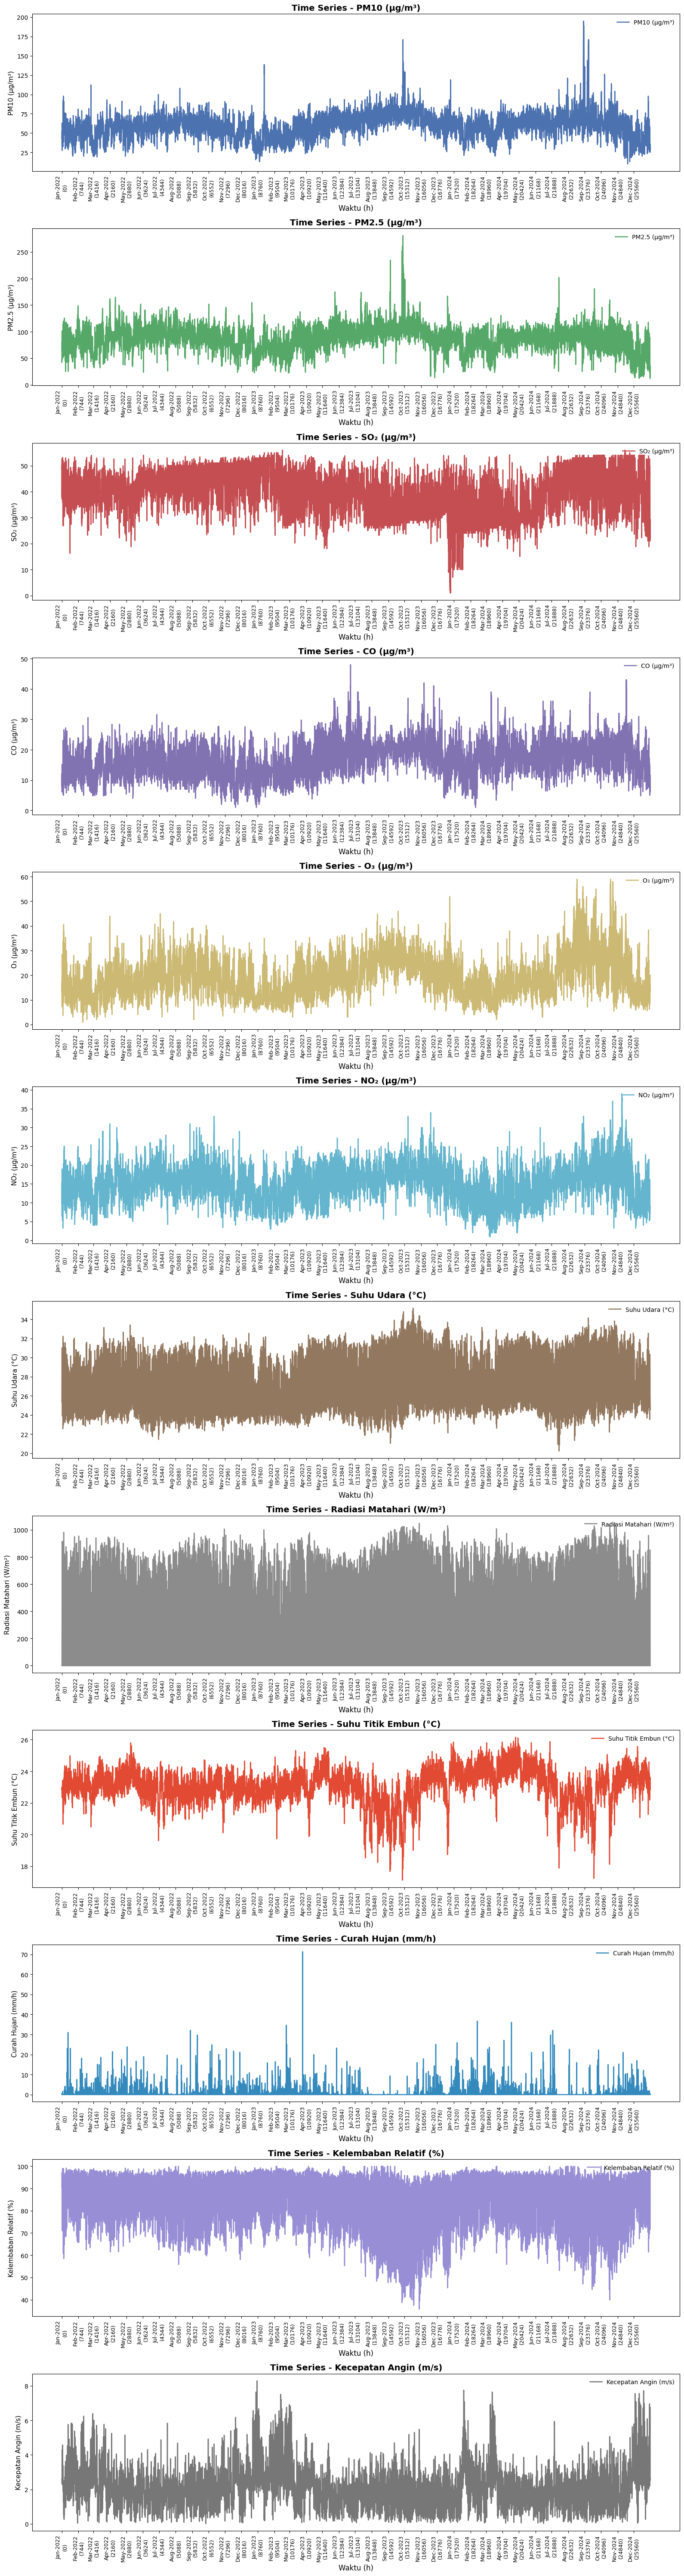

In [16]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)
df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [17]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,59.67,87.44,39.37,16.73,19.15,15.07,26.86,217.01,23.04,0.61,85.29,2.04
std,16.23,24.87,9.48,6.17,8.57,5.19,2.58,290.45,1.08,2.08,12.37,1.14
min,10.00,12.00,1.00,1.00,1.00,1.00,20.23,0.00,17.12,-0.00,35.73,0.01
25%,50.80,71.80,31.00,12.00,13.00,11.60,24.72,0.00,22.51,-0.00,76.49,1.27
50%,61.00,89.00,40.00,16.80,18.00,15.00,26.24,14.00,23.14,-0.00,90.50,1.83
75%,69.40,103.00,47.00,21.00,24.00,18.20,28.92,437.00,23.74,0.21,95.35,2.54
max,195.00,281.00,56.00,48.00,59.00,39.00,35.17,1053.00,26.15,71.27,100.00,8.29


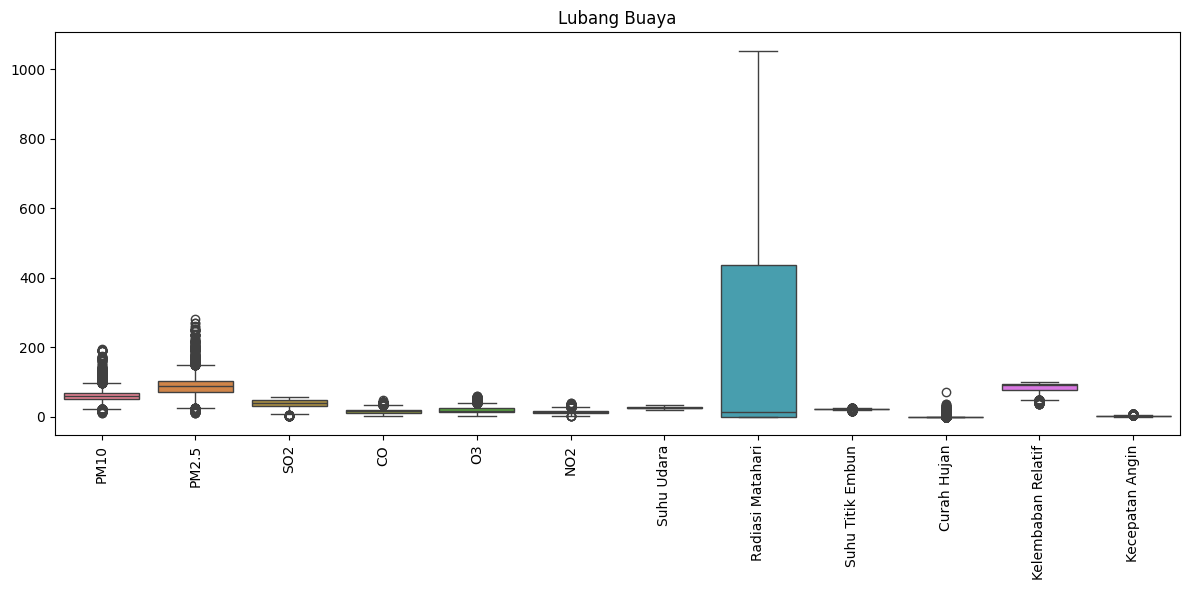

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_imputed)
plt.xticks(rotation=90)
plt.title("Lubang Buaya")
plt.tight_layout()
plt.show()